# V-JEPA phase composites — RAW fields

Same 8 phases as `1-jepa_inference.ipynb`, but composited on the **raw, absolute** OLR and
U850 fields (the original NetCDF data, units W m$^{-2}$ and m s$^{-1}$) rather than the
standardized WH04 anomalies.

- **Classification:** reused verbatim from `runs/vjepa/phase_labels.npz` (already ordered
  eastward by convective longitude when it was saved).
- **Raw fields:** loaded with `jepa.data.anomaly.load_raw_fields_2d` — the same loader the
  preprocessing uses, 15°N–15°S, full periodic longitude, 2.5° grid.

Note: a raw composite is dominated by the **climatology** (mean OLR ~ 230–280 W m$^{-2}$),
so the MJO signal is a small perturbation on a large background — the phase-to-phase
differences are subtle.  The last figure removes the all-phase mean to isolate the MJO
structure for comparison with the anomaly composite.

## 0. Imports, config, saved labels

In [6]:
import os, sys, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = "/glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO"
sys.path.insert(0, ROOT); os.chdir(ROOT)
from jepa.data.anomaly import load_raw_fields_2d

with open(os.path.join(ROOT, "jepa/config_vjepa.yaml")) as f:
    cfg = yaml.safe_load(f)
d = cfg["data"]
OUT = os.path.join(ROOT, "runs/vjepa")
k = 10
# saved V-JEPA classification (eastward-ordered) from 1-jepa_inference.ipynb
z = np.load(os.path.join(OUT, f"phase_{k}_labels.npz"), allow_pickle=True)
lab_dates = z["dates"].astype("datetime64[D]")
lab_km    = z["kmeans"]
lab_som   = z["som"]
k = int(max(lab_km.max(), lab_som.max()) + 1)
print("loaded labels:", lab_km.shape, "| k =", k,
      "|", str(lab_dates[0]), "->", str(lab_dates[-1]))
print("phase counts (kmeans):", np.bincount(lab_km, minlength=k))

loaded labels: (15220,) | k = 10 | 1979-05-02 -> 2020-12-31
phase counts (kmeans): [1380 1126 1217 1686 1265 1615 1808 1800 1438 1885]


In [3]:
k

8

## 1. Load the raw OLR / U850 fields

`load_raw_fields_2d` reads the original `olr.day.mean.nc` and `uwnd.YYYY.nc`, restricts to
the 15°N–15°S band, inner-joins on the common daily time axis, and returns (time, lat, lon)
arrays.  Run this on a compute node — loading the full record needs a few hundred MB.

In [7]:
fields = load_raw_fields_2d(
    data_root=d["data_root"],
    year_start=d["year_start"], year_end=d["year_end"],
    lat_band=tuple(d["lat_band"]),
)
olr = fields["olr"]   # (time, lat, lon)  W/m^2
u85 = fields["u850"]  # (time, lat, lon)  m/s
lat = olr.lat.values; lon = olr.lon.values
ftime = olr.time.values.astype("datetime64[D]")
print("raw OLR :", olr.shape, "  range %.0f..%.0f W/m^2" % (float(olr.min()), float(olr.max())))
print("raw U850:", u85.shape, "  range %.1f..%.1f m/s" % (float(u85.min()), float(u85.max())))
print("grid:", lat.size, "lat x", lon.size, "lon")

raw OLR : (15341, 13, 144)   range 65..343 W/m^2
raw U850: (15341, 13, 144)   range -28.1..34.2 m/s
grid: 13 lat x 144 lon


## 2. Composite the raw fields per phase

Map each labelled day to its row in the raw time axis, then average the raw OLR and U850
over all days assigned to each phase.

In [8]:
LAB = lab_km            # switch to lab_som to composite the SOM phases instead
pos = pd.Index(ftime).get_indexer(lab_dates)   # label-day -> raw-field row (-1 if absent)

comp_olr = np.full((k, lat.size, lon.size), np.nan)
comp_u   = np.full((k, lat.size, lon.size), np.nan)
centre_lon = np.full(k, np.nan)
nday = np.zeros(k, int)
olr_v, u_v = olr.values, u85.values
for c in range(k):
    rows = pos[(LAB == c) & (pos >= 0)]
    nday[c] = rows.size
    if rows.size == 0:
        continue
    comp_olr[c] = olr_v[rows].mean(0)
    comp_u[c]   = u_v[rows].mean(0)
    centre_lon[c] = lon[int(np.argmin(comp_olr[c].mean(0)))]  # min raw OLR longitude
print("days per phase     :", nday)
print("raw-OLR min lon (E):", np.round(centre_lon).astype(int))

days per phase     : [1380 1126 1217 1686 1265 1615 1808 1800 1438 1885]
raw-OLR min lon (E): [288  95  98 110  95  98 288 290  98 140]


## 3. Raw phase composites — OLR shading (W m$^{-2}$) + U850 contours (m s$^{-1}$)

Dark blue = low OLR = deep convection.  These are absolute fields, so all panels share the
tropical-OLR background; look for where the convective minimum and the low-level westerly
band sit in each phase.

saved /glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO/runs/vjepa/phase_composites_raw.png


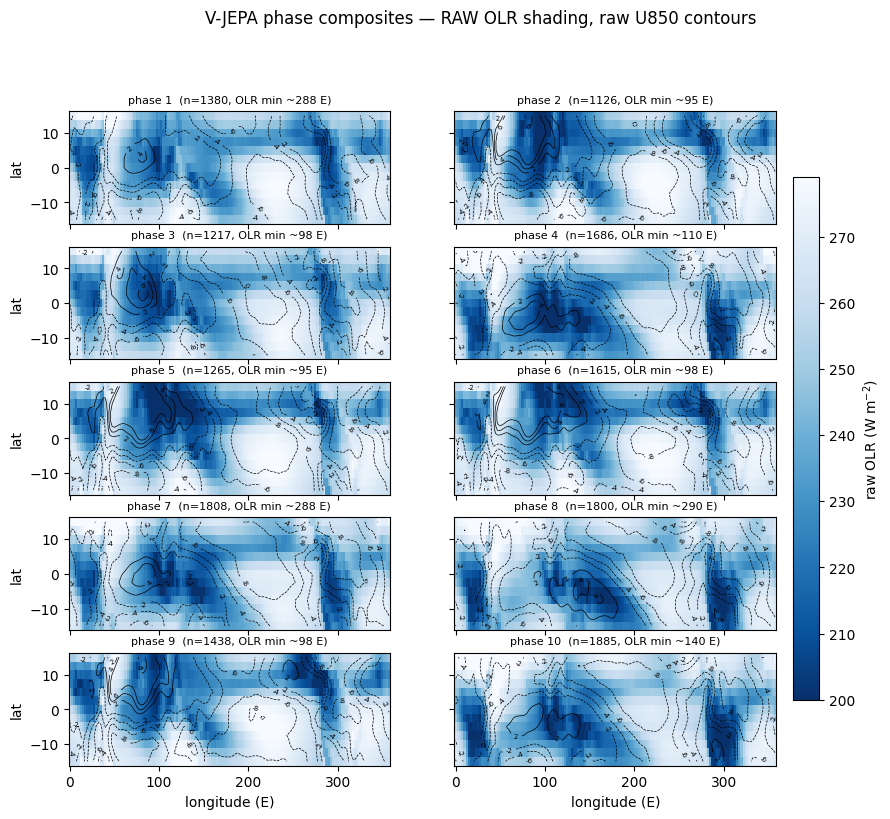

In [9]:
vmin, vmax = np.nanpercentile(comp_olr, [2, 98])
ulev = [-8, -6, -4, -2, 2, 4, 6]
nrow = (k + 1) // 2
fig, axes = plt.subplots(nrow, 2, figsize=(11, 1.7*nrow), sharex=True, sharey=True)
for c, ax in zip(range(k), axes.ravel()):
    pm = ax.pcolormesh(lon, lat, comp_olr[c], cmap="Blues_r", vmin=vmin, vmax=vmax,
                       shading="nearest")
    cs = ax.contour(lon, lat, comp_u[c], levels=ulev, colors="k", linewidths=0.5)
    ax.clabel(cs, fmt="%d", fontsize=5)
    ax.set_title(f"phase {c+1}  (n={nday[c]}, OLR min ~{centre_lon[c]:.0f} E)", fontsize=8)
for a in axes[-1]: a.set_xlabel("longitude (E)")
for a in axes[:, 0]: a.set_ylabel("lat")
fig.colorbar(pm, ax=axes, shrink=0.8, pad=0.02, label="raw OLR (W m$^{-2}$)")
fig.suptitle("V-JEPA phase composites — RAW OLR shading, raw U850 contours", y=1.0)
fpath = os.path.join(OUT, "phase_composites_raw.png")
fig.savefig(fpath, dpi=120, bbox_inches="tight")
print("saved", fpath)
plt.show()

## 4. Raw minus all-phase mean — the MJO signal isolated

Subtracting the average over all phases removes the climatology and recovers the
eastward-marching convective dipole (this is essentially the anomaly composite, shown here
for direct comparison with the raw panels above).

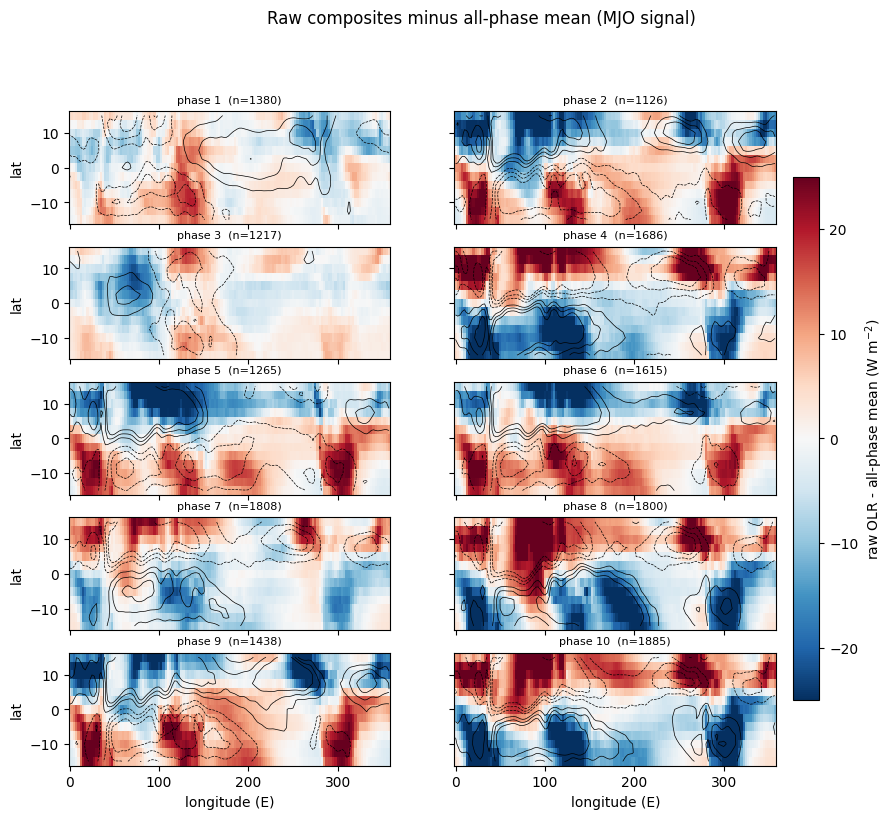

In [10]:
bg_olr = np.nanmean(comp_olr, axis=0)
bg_u   = np.nanmean(comp_u,   axis=0)
fig, axes = plt.subplots(nrow, 2, figsize=(11, 1.7*nrow), sharex=True, sharey=True)
for c, ax in zip(range(k), axes.ravel()):
    pm = ax.pcolormesh(lon, lat, comp_olr[c] - bg_olr, cmap="RdBu_r",
                       vmin=-25, vmax=25, shading="nearest")
    ax.contour(lon, lat, comp_u[c] - bg_u, levels=[-3,-2,-1,1,2,3],
               colors="k", linewidths=0.5)
    ax.set_title(f"phase {c+1}  (n={nday[c]})", fontsize=8)
for a in axes[-1]: a.set_xlabel("longitude (E)")
for a in axes[:, 0]: a.set_ylabel("lat")
fig.colorbar(pm, ax=axes, shrink=0.8, pad=0.02, label="raw OLR - all-phase mean (W m$^{-2}$)")
fig.suptitle("Raw composites minus all-phase mean (MJO signal)", y=1.0)
fig.savefig(os.path.join(OUT, "phase_composites_raw_demean.png"), dpi=120, bbox_inches="tight")
plt.show()

In [11]:
OUT

'/glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO/runs/vjepa'

## Summary

- Classification reused from `runs/vjepa/phase_labels.npz` (V-JEPA k-means phases).
- Composites built on the **raw** OLR/U850 fields (`load_raw_fields_2d`), not anomalies.
- Figures saved: `runs/vjepa/phase_composites_raw.png` (absolute fields) and
  `phase_composites_raw_demean.png` (climatology removed).
- To composite the SOM phases instead, set `LAB = lab_som` in §2 and re-run.